# 🛒 AI Sales Forecasting — Explore & Model
**Goal:** predict how many units of each item each store will sell over the next 90 days,
and check which model does it best.

**Data:** Kaggle *Store Item Demand Forecasting Challenge* — 5 years (2013–2017) of daily sales
for 50 items in 10 stores = 500 time series, 913,000 rows.

Steps: 1) load & clean → 2) explore with charts → 3) features → 4) baselines →
5) Prophet, XGBoost, LightGBM → 6) leaderboard + time-series cross-validation →
7) SHAP explanations → 8) prediction intervals → 9) anomalies → 10) save models for the app.

In [1]:
# --- Setup -------------------------------------------------------------
# In Google Colab, first run:  !git clone <your repo>  and  %cd sales-forecaster
# then:  !pip install -r requirements.txt
import sys, os, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # so "import src..." works
os.makedirs(ROOT / "images", exist_ok=True); os.makedirs(ROOT / "models", exist_ok=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from src.data import load_sales
from src.features import make_features, feature_columns, holiday_calendar, islamic_dates, COUNTRY
from src import models as M
from src.forecast import detect_anomalies
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})

## 1. Load and clean the data

In [2]:
df = load_sales(ROOT / "data" / "train.csv")   # cleaning: types, duplicates, missing days
print(df.shape); print(df["date"].min().date(), "→", df["date"].max().date())
print("stores:", df["store"].nunique(), "| items:", df["item"].nunique(), "| missing values:", df.isna().sum().sum())
df.head()

(913000, 4)
2013-01-01 → 2017-12-31
stores: 10 | items: 50 | missing values: 0


,date,store,item,sales
0,2013-01-01,1,1,13.0
1,2013-01-02,1,1,11.0
2,2013-01-03,1,1,14.0
3,2013-01-04,1,1,13.0
4,2013-01-05,1,1,10.0


## 2. Explore: trend, weekday, month, holidays

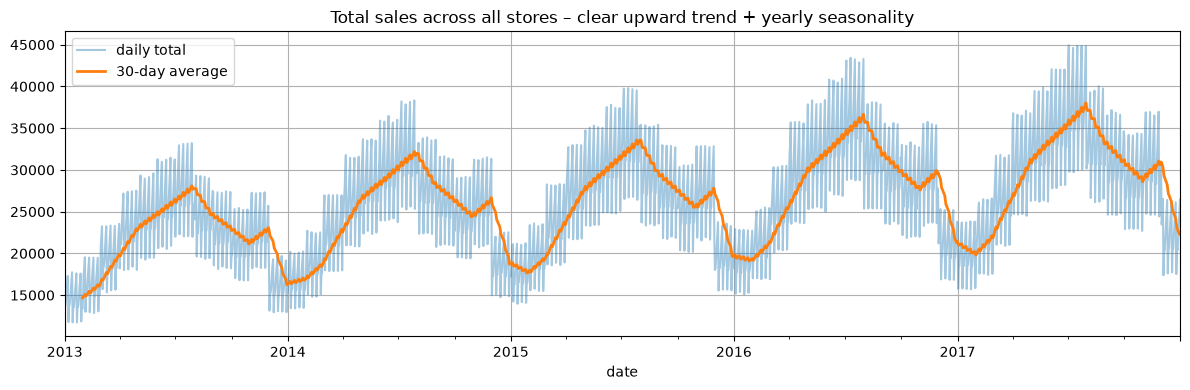

In [3]:
daily = df.groupby("date")["sales"].sum()
ax = daily.plot(alpha=.4, label="daily total")
daily.rolling(30).mean().plot(ax=ax, lw=2, label="30-day average")
ax.set_title("Total sales across all stores – clear upward trend + yearly seasonality"); ax.legend()
plt.tight_layout(); plt.savefig(ROOT / "images" / "trend.png", dpi=110); plt.show()

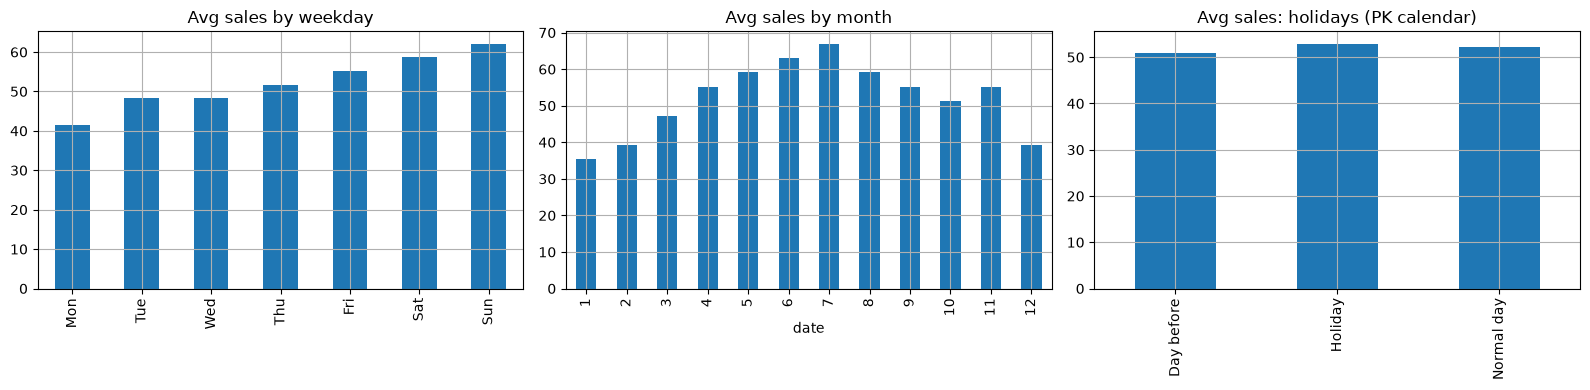

{'Mon': 41.400001525878906, 'Tue': 48.20000076293945, 'Wed': 48.400001525878906, 'Thu': 51.70000076293945, 'Fri': 55.20000076293945, 'Sat': 58.70000076293945, 'Sun': 62.099998474121094}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
wd = df.groupby(df["date"].dt.dayofweek)["sales"].mean()
wd.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]; wd.plot.bar(ax=axes[0], title="Avg sales by weekday")
df.groupby(df["date"].dt.month)["sales"].mean().plot.bar(ax=axes[1], title="Avg sales by month")
hol = holiday_calendar(df["date"].min(), df["date"].max())
tag = np.where(df["date"].isin(hol), "Holiday", np.where((df["date"] + pd.Timedelta(days=1)).isin(hol), "Day before", "Normal day"))
df.groupby(tag)["sales"].mean().plot.bar(ax=axes[2], title=f"Avg sales: holidays ({COUNTRY} calendar)")
plt.tight_layout(); plt.savefig(ROOT / "images" / "seasonality.png", dpi=110); plt.show()
print(wd.round(1).to_dict())

**What we learn:** weekends (especially Sunday) sell the most, July is the peak month, and sales grow each year. Holidays have only a small effect in this dataset.

## 3. Feature engineering (see `src/features.py`)

In [5]:
feat = make_features(df)
train, test, cutoff = M.time_split(feat, test_days=90)   # last 90 days = test
print("features:", feature_columns(feat))
print("train:", train.date.min().date(), "→", train.date.max().date(), "| test:", test.date.min().date(), "→", test.date.max().date())

features: ['store', 'item', 'dayofweek', 'month', 'dayofmonth', 'dayofyear', 'weekofyear', 'year', 'is_weekend', 'is_month_start', 'is_month_end', 'is_holiday', 'is_pre_holiday', 'ramadan_day', 'is_ramadan', 'is_eid_fitr', 'days_to_eid_fitr', 'days_after_eid_fitr', 'is_eid_adha', 'days_to_eid_adha', 'days_after_eid_adha', 'lag_91', 'lag_98', 'lag_105', 'lag_112', 'lag_119', 'lag_126', 'lag_182', 'lag_364', 'lag_371', 'lag_546', 'lag_728', 'roll_mean_7', 'roll_mean_28', 'roll_mean_91', 'roll_mean_182', 'roll_mean_364', 'roll_std_28', 'same_wday_mean']
train: 2013-01-01 → 2017-10-02 | test: 2017-10-03 → 2017-12-31


## 4–5. Baselines, Prophet, XGBoost, LightGBM on the 90-day hold-out

In [6]:
preds, times = {}, {}
t = time.time(); preds["Naive (last year)"] = M.naive_last_year(test); times["Naive (last year)"] = time.time() - t
t = time.time(); preds["Moving avg (28d)"] = M.moving_average(train, test); times["Moving avg (28d)"] = time.time() - t

t = time.time(); xgb_model = M.train_xgboost(train); preds["XGBoost"] = M.predict(xgb_model, test); times["XGBoost"] = time.time() - t
t = time.time(); lgb_model = M.train_lightgbm(train); preds["LightGBM"] = M.predict(lgb_model, test); times["LightGBM"] = time.time() - t

# Prophet: one model per store-item series (500 fits, run in parallel)
t = time.time()
# Prophet gets the same holiday calendar; in Pakistan mode Ramadan is a separate
# "holiday" event (whole month) and the 7 days before each Eid count as a shopping rush.
hdf = pd.DataFrame({"holiday": "holiday", "ds": holiday_calendar(df.date.min(), df.date.max())})
if COUNTRY == "PK":
    isl = islamic_dates(df.date.min().year, df.date.max().year + 1)
    ram = pd.DataFrame({"holiday": "ramadan", "ds": isl.ramadan_start, "lower_window": 0, "upper_window": 29})
    rush = pd.DataFrame({"holiday": "eid_rush", "ds": pd.concat([isl.eid_fitr, isl.eid_adha]).dropna(), "lower_window": -7, "upper_window": 0})
    hdf = pd.concat([hdf.assign(lower_window=0, upper_window=0), ram, rush], ignore_index=True)
pfc = M.prophet_forecast(train[["date","store","item","sales"]], sorted(test.date.unique()), hdf)
p_test = test[["date","store","item"]].merge(pfc, on=["date","store","item"], how="left")
preds["Prophet"] = p_test["yhat"].values; times["Prophet"] = time.time() - t

23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing


23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing


23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] start processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing


23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:32 - cmdstanpy - INFO - Chain [1] done processing
23:30:33 - cmdstanpy - INFO - Chain [1] done processing
23:30:33 - cmdstanpy - INFO - Chain [1] start processing
23:30:33 - cmdstanpy - INFO - Chain [1] start processing


23:30:33 - cmdstanpy - INFO - Chain [1] start processing
23:30:33 - cmdstanpy - INFO - Chain [1] start processing
23:30:33 - cmdstanpy - INFO - Chain [1] start processing
23:30:33 - cmdstanpy - INFO - Chain [1] start processing
23:30:33 - cmdstanpy - INFO - Chain [1] done processing
23:30:33 - cmdstanpy - INFO - Chain [1] done processing
23:30:33 - cmdstanpy - INFO - Chain [1] done processing
23:30:33 - cmdstanpy - INFO - Chain [1] done processing
23:30:33 - cmdstanpy - INFO - Chain [1] done processing


...

23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing


23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing


23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing


23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] done processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:53 - cmdstanpy - INFO - Chain [1] start processing
23:30:54 - cmdstanpy - INFO - Chain [1] done processing


23:30:54 - cmdstanpy - INFO - Chain [1] done processing
23:30:54 - cmdstanpy - INFO - Chain [1] done processing


In [7]:
board = pd.DataFrame([{"model": k, **M.metrics(test["sales"], v), "train+predict sec": times[k]} for k, v in preds.items()])
board = board.sort_values("MAE").reset_index(drop=True)
board.to_csv(ROOT / "models" / "leaderboard_holdout.csv", index=False)
board.round(3)

,model,MAE,MAPE %,SMAPE %,train+predict sec
0,LightGBM,5.895,12.915,12.419,8.827
1,XGBoost,5.907,13.016,12.411,9.933
2,Prophet,6.357,14.160,13.225,24.491
3,Naive (last year),8.350,17.692,17.865,0.000
4,Moving avg (28d),11.754,26.938,22.253,0.432


## 6. Time-series cross-validation (3 expanding-window folds × 90 days)

In [8]:
cv = M.time_series_cv(feat, n_folds=3, horizon=90)
cv_summary = cv.groupby("model")[["MAE","MAPE %","SMAPE %"]].agg(["mean","std"]).round(3).sort_values(("MAE","mean"))
cv.to_csv(ROOT / "models" / "cv_folds.csv", index=False)
cv_summary.columns = [" ".join(c) for c in cv_summary.columns]; cv_summary.reset_index().to_csv(ROOT / "models" / "cv_summary.csv", index=False)
display(cv.round(3)); cv_summary

,fold,model,MAE,MAPE %,SMAPE %
0,2017-04-06 → 2017-07-04,Naive (last year),9.104,15.561,15.741
1,2017-04-06 → 2017-07-04,Moving avg (28d),14.303,20.261,22.861
2,2017-04-06 → 2017-07-04,LightGBM,6.459,11.368,10.998
3,2017-04-06 → 2017-07-04,XGBoost,6.504,11.348,11.028
4,2017-07-05 → 2017-10-02,Naive (last year),9.199,15.561,15.823
5,2017-07-05 → 2017-10-02,Moving avg (28d),11.081,19.417,17.330
6,2017-07-05 → 2017-10-02,LightGBM,6.518,11.551,11.073
7,2017-07-05 → 2017-10-02,XGBoost,6.610,11.764,11.184
8,2017-10-03 → 2017-12-31,Naive (last year),8.350,17.692,17.865
9,2017-10-03 → 2017-12-31,Moving avg (28d),11.754,26.938,22.253


,MAE mean,MAE std,MAPE % mean,MAPE % std,SMAPE % mean,SMAPE % std
model,,,,,,
LightGBM,6.291,0.344,11.945,0.845,11.497,0.800
XGBoost,6.340,0.379,12.042,0.869,11.541,0.758
Naive (last year),8.885,0.465,16.271,1.231,16.477,1.204
Moving avg (28d),12.379,1.700,22.205,4.120,20.815,3.033


## Forecast vs actual (one store-item, plus the total)

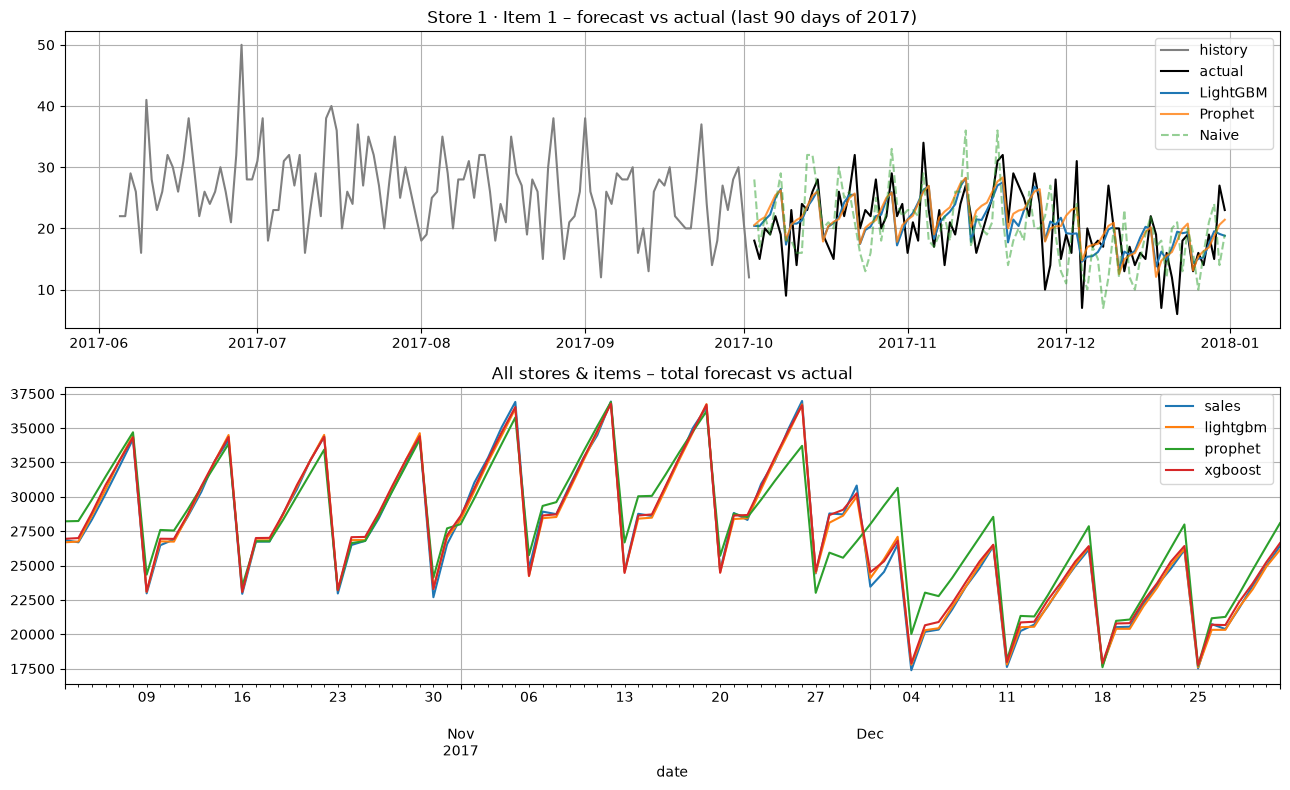

In [9]:
# keep predictions in a separate table so they don't get mistaken for features later
res = test[["date","store","item","sales"]].assign(**{k.split()[0].lower(): v for k, v in preds.items()})
s = res[(res.store == 1) & (res.item == 1)]
hist = train[(train.store == 1) & (train.item == 1) & (train.date >= cutoff - pd.Timedelta(days=120))]
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
axes[0].plot(hist.date, hist.sales, color="grey", label="history")
axes[0].plot(s.date, s.sales, "k", label="actual")
axes[0].plot(s.date, s.lightgbm, label="LightGBM"); axes[0].plot(s.date, s.prophet, label="Prophet", alpha=.8)
axes[0].plot(s.date, s.naive, label="Naive", alpha=.5, ls="--")
axes[0].set_title("Store 1 · Item 1 – forecast vs actual (last 90 days of 2017)"); axes[0].legend()
tot = res.groupby("date")[["sales","lightgbm","prophet","xgboost"]].sum()
tot.plot(ax=axes[1], title="All stores & items – total forecast vs actual")
plt.tight_layout(); plt.savefig(ROOT / "images" / "forecast_vs_actual.png", dpi=110); plt.show()

## 7. SHAP – *why* does the tree model predict what it predicts?

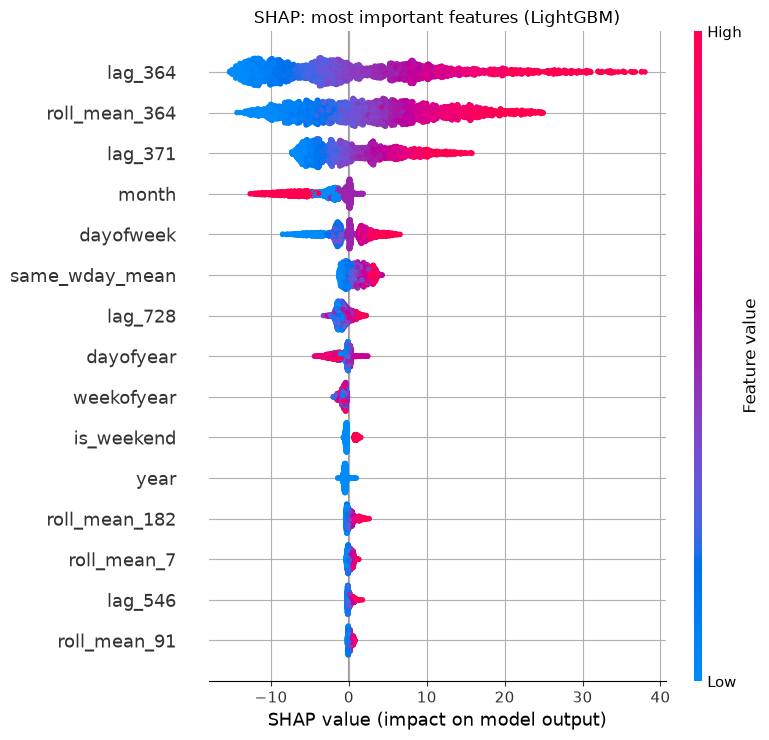

,feature,mean_abs_shap
28,lag_364,9.034692
36,roll_mean_364,7.305797
29,lag_371,4.231421
3,month,3.502060
2,dayofweek,2.254546
38,same_wday_mean,1.328738
31,lag_728,0.920760
5,dayofyear,0.887811
6,weekofyear,0.746478
8,is_weekend,0.537584


In [10]:
import shap
sample = test.sample(3000, random_state=0)[feature_columns(feat)]
explainer = shap.TreeExplainer(lgb_model)
sv = explainer.shap_values(sample)
shap.summary_plot(sv, sample, show=False, max_display=15)
plt.title("SHAP: most important features (LightGBM)"); plt.tight_layout()
plt.savefig(ROOT / "images" / "shap_summary.png", dpi=110, bbox_inches="tight"); plt.show()
imp = pd.DataFrame({"feature": sample.columns, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
imp.to_csv(ROOT / "models" / "shap_importance.csv", index=False); imp.head(10)

## 8. Prediction intervals (80%) with quantile LightGBM — how often does reality land inside?

In [11]:
lo_model = M.train_lightgbm(train, objective="quantile", alpha=0.1)
hi_model = M.train_lightgbm(train, objective="quantile", alpha=0.9)
lo, hi = M.predict(lo_model, test), M.predict(hi_model, test)
cov_lgb = ((test.sales >= lo) & (test.sales <= hi)).mean() * 100
cov_pro = ((test.sales.values >= p_test.yhat_lower.values) & (test.sales.values <= p_test.yhat_upper.values)).mean() * 100
print(f"80% interval coverage on test – LightGBM quantile: {cov_lgb:.1f}% | Prophet: {cov_pro:.1f}%")
pd.Series({"lightgbm_quantile_coverage_pct": cov_lgb, "prophet_coverage_pct": cov_pro}).to_csv(ROOT / "models" / "interval_coverage.csv")

80% interval coverage on test – LightGBM quantile: 78.9% | Prophet: 76.0%


## 9. Anomaly detection on past sales

anomalous days found for store 1 item 1: 7


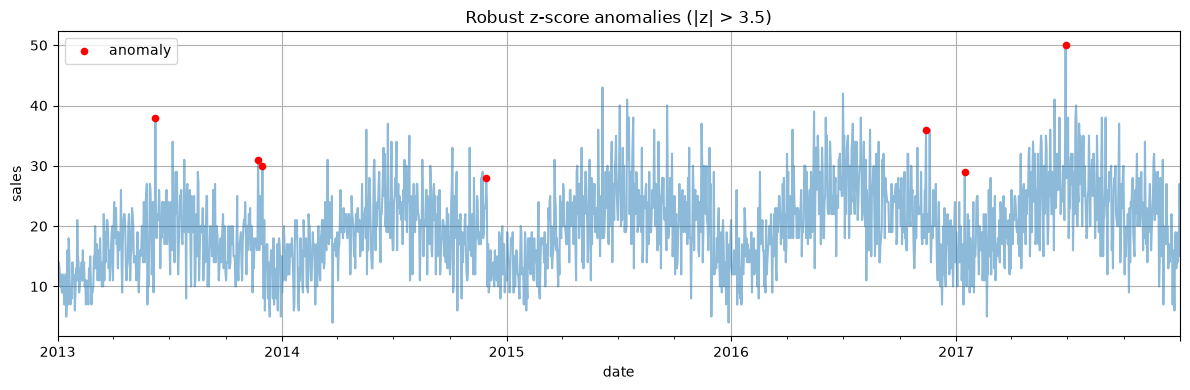

,date,sales,expected,robust_z,is_anomaly
159,2013-06-09,38.0,21.0,3.822167,True
326,2013-11-23,31.0,17.0,4.721500,True
333,2013-11-30,30.0,17.0,4.384250,True
697,2014-11-29,28.0,17.5,3.541125,True
1412,2016-11-13,36.0,22.0,4.721500,True
1475,2017-01-15,29.0,15.0,4.196889,True
1639,2017-06-28,50.0,28.0,3.957067,True


In [12]:
an = detect_anomalies(df[(df.store == 1) & (df.item == 1)][["date","sales"]])
print("anomalous days found for store 1 item 1:", an.is_anomaly.sum())
ax = an.set_index("date")["sales"].plot(alpha=.5)
an[an.is_anomaly].plot.scatter(x="date", y="sales", color="red", ax=ax, label="anomaly", zorder=3)
ax.set_title("Robust z-score anomalies (|z| > 3.5)"); plt.tight_layout(); plt.show()
an[an.is_anomaly].head(10)

## 10. Retrain on ALL data and save the models for the Streamlit app

In [13]:
final = {"point": M.train_lightgbm(feat), "lower": M.train_lightgbm(feat, objective="quantile", alpha=0.1),
         "upper": M.train_lightgbm(feat, objective="quantile", alpha=0.9)}
joblib.dump(final, ROOT / "models" / "lgbm_models.joblib")
print("saved models/lgbm_models.joblib")

saved models/lgbm_models.joblib


## Next steps / ideas
* Tune hyper-parameters with Optuna · retrain on real Lahore shop data, where the Pakistan calendar (Ramadan, Eid) should really matter
* Add price/promotion columns if your shop records them · try deep learning (N-BEATS, TFT)